# 04 · Explainable AI: six attribution methods, sanity checks and faithfulness

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/v2/notebooks/04_explainable_ai.ipynb)

Grad-CAM, Grad-CAM++, Integrated Gradients (Captum), occlusion sensitivity, and KernelSHAP and LIME on the same SLIC superpixels, checked with the cascading model-parameter randomisation test (Adebayo et al., 2018) and scored with deletion / insertion AUC (Petsiuk et al., 2018). Set `FORCE_XAI = True` / `FORCE_LIME = True` to recompute the studies on CPU.

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)
    os.chdir("brain-tumor-mri-classification/v2")  # this notebook belongs to the v2 code in v2/
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # -> v2/
elif os.path.isdir("v2"):
    os.chdir("v2")  # started from the repository root
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo/v2


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from btmri import CLASSES, CLASS_LABELS
from btmri.model import build_model
from btmri.xai import GreyModel, explain, METHODS, METHOD_LABELS, deletion_insertion
from btmri.data import download_dataset, load_gray_square
model = build_model(pretrained=False)
model.load_state_dict(torch.load("results/runs/clean/best.pt", map_location="cpu")); model.eval()
gm = GreyModel(model).eval()
root = download_dataset()
pred = pd.read_csv("results/predictions/clean_test_predictions.csv")

### Live example: all six methods on one test slice per class

/tmp/ipykernel_455526/2143556613.py:5: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  x = torch.from_numpy(load_gray_square(str(root / r.relpath), 224)).float().div(255)[None, None]


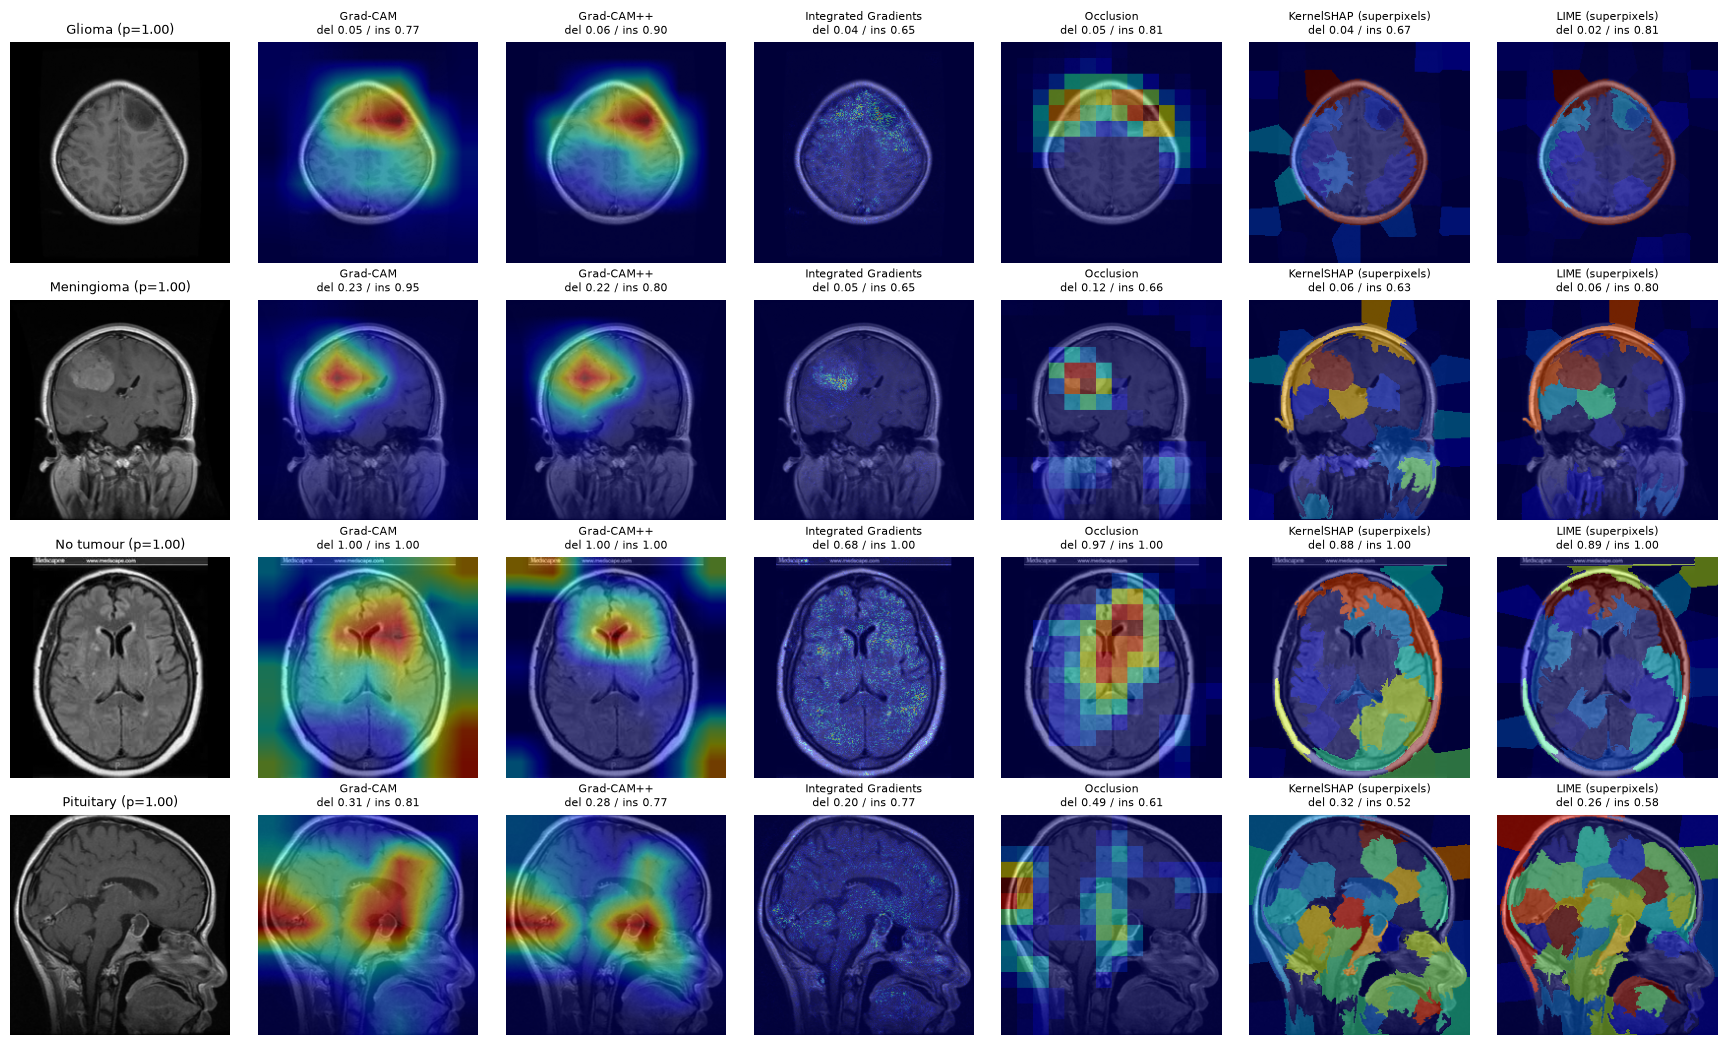

In [4]:
ALL = METHODS + ["lime"]
fig, axes = plt.subplots(4, 7, figsize=(17.5, 10.5))
for i, c in enumerate(CLASSES):
    r = pred[(pred.true == c) & (pred.pred == c)].sample(1, random_state=3).iloc[0]
    x = torch.from_numpy(load_gray_square(str(root / r.relpath), 224)).float().div(255)[None, None]
    k = CLASSES.index(r.pred)
    axes[i, 0].imshow(x[0, 0], cmap="gray"); axes[i, 0].set_title(f"{CLASS_LABELS[c]} (p={r.confidence:.2f})", fontsize=9)
    for j, mth in enumerate(ALL):
        s = explain(gm, x, k, mth)
        d, ins = deletion_insertion(gm, x, k, s)
        axes[i, j + 1].imshow(x[0, 0], cmap="gray"); axes[i, j + 1].imshow(s, cmap="jet", alpha=0.45)
        axes[i, j + 1].set_title(f"{METHOD_LABELS[mth]}\ndel {d:.2f} / ins {ins:.2f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Full study (100 test images, 25 per class; 12 images for the sanity check)

In [5]:
FORCE_XAI = False
if FORCE_XAI or not Path("results/xai/faithfulness_summary.csv").exists():
    subprocess.run([sys.executable, "scripts/run_xai.py"], check=True)
faith = pd.read_csv("results/xai/faithfulness_per_image.csv")
display(faith.groupby("method")[["deletion_auc", "insertion_auc", "inside_foreground"]].agg(["mean", "std"]).round(3))
san = pd.read_csv("results/xai/sanity_cascading_randomisation.csv")
display(san.groupby(["method", "stage"], sort=False).spearman.mean().unstack().round(3))
display(pd.read_csv("results/xai/method_agreement_spearman.csv", index_col=0).round(3))

deletion_auc        insertion_auc         \
                             mean    std          mean    std   
method                                                          
gradcam                     0.487  0.355         0.841  0.195   
gradcampp                   0.490  0.353         0.842  0.183   
integrated_gradients        0.283  0.259         0.679  0.252   
kernel_shap                 0.400  0.351         0.749  0.254   
occlusion                   0.466  0.333         0.803  0.226   
random                      0.283  0.149         0.497  0.366   

                     inside_foreground         
                                  mean    std  
method                                         
gradcam                          0.792  0.123  
gradcampp                        0.840  0.137  
integrated_gradients             0.978  0.018  
kernel_shap                      0.765  0.093  
occlusion                        0.827  0.108  
random                           0.579  0.136

stage,classifier,conv_head,blocks.6,blocks.4,blocks.2,conv_stem
method,,,,,,
gradcam,0.112,0.079,0.010,0.024,0.007,-0.068
gradcampp,0.943,0.804,0.509,0.373,0.350,0.075
integrated_gradients,0.941,0.936,0.934,0.915,0.891,0.836
occlusion,0.136,0.038,0.229,0.068,0.063,0.027
kernel_shap,0.242,0.021,0.051,0.169,0.174,0.205


,gradcam,gradcampp,integrated_gradients,occlusion,kernel_shap
gradcam,1.000,0.840,0.513,0.382,0.222
gradcampp,0.840,1.000,0.581,0.313,0.218
integrated_gradients,0.513,0.581,1.000,0.307,0.279
occlusion,0.382,0.313,0.307,1.000,0.182
kernel_shap,0.222,0.218,0.279,0.182,1.000


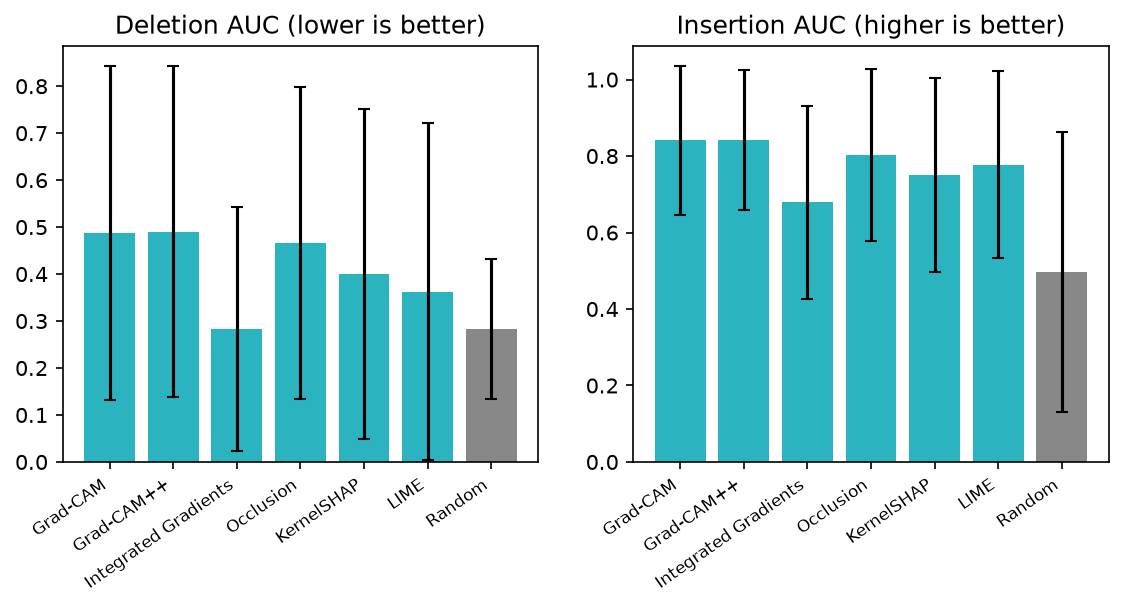

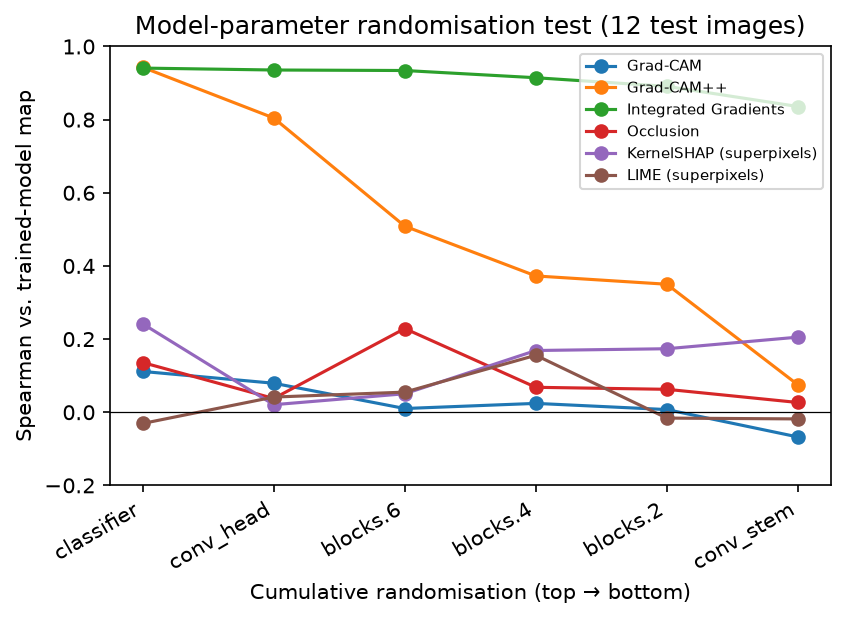

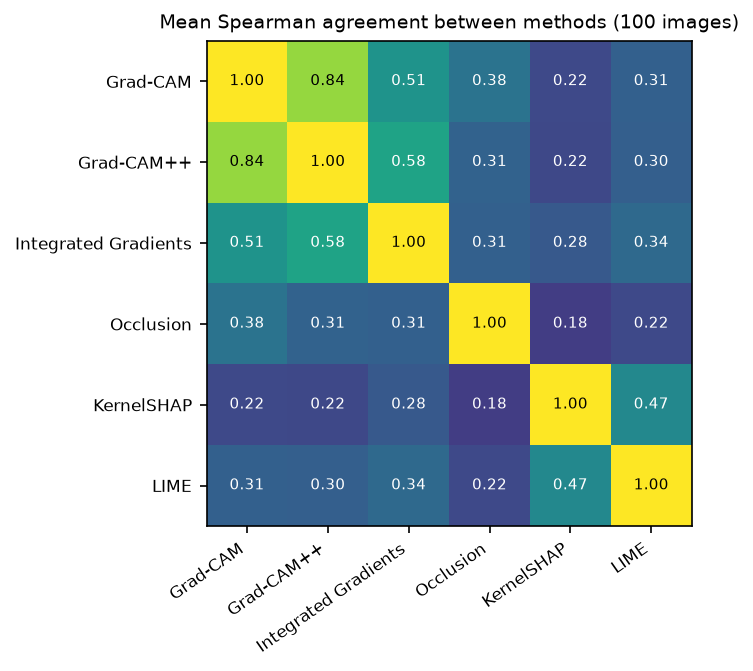

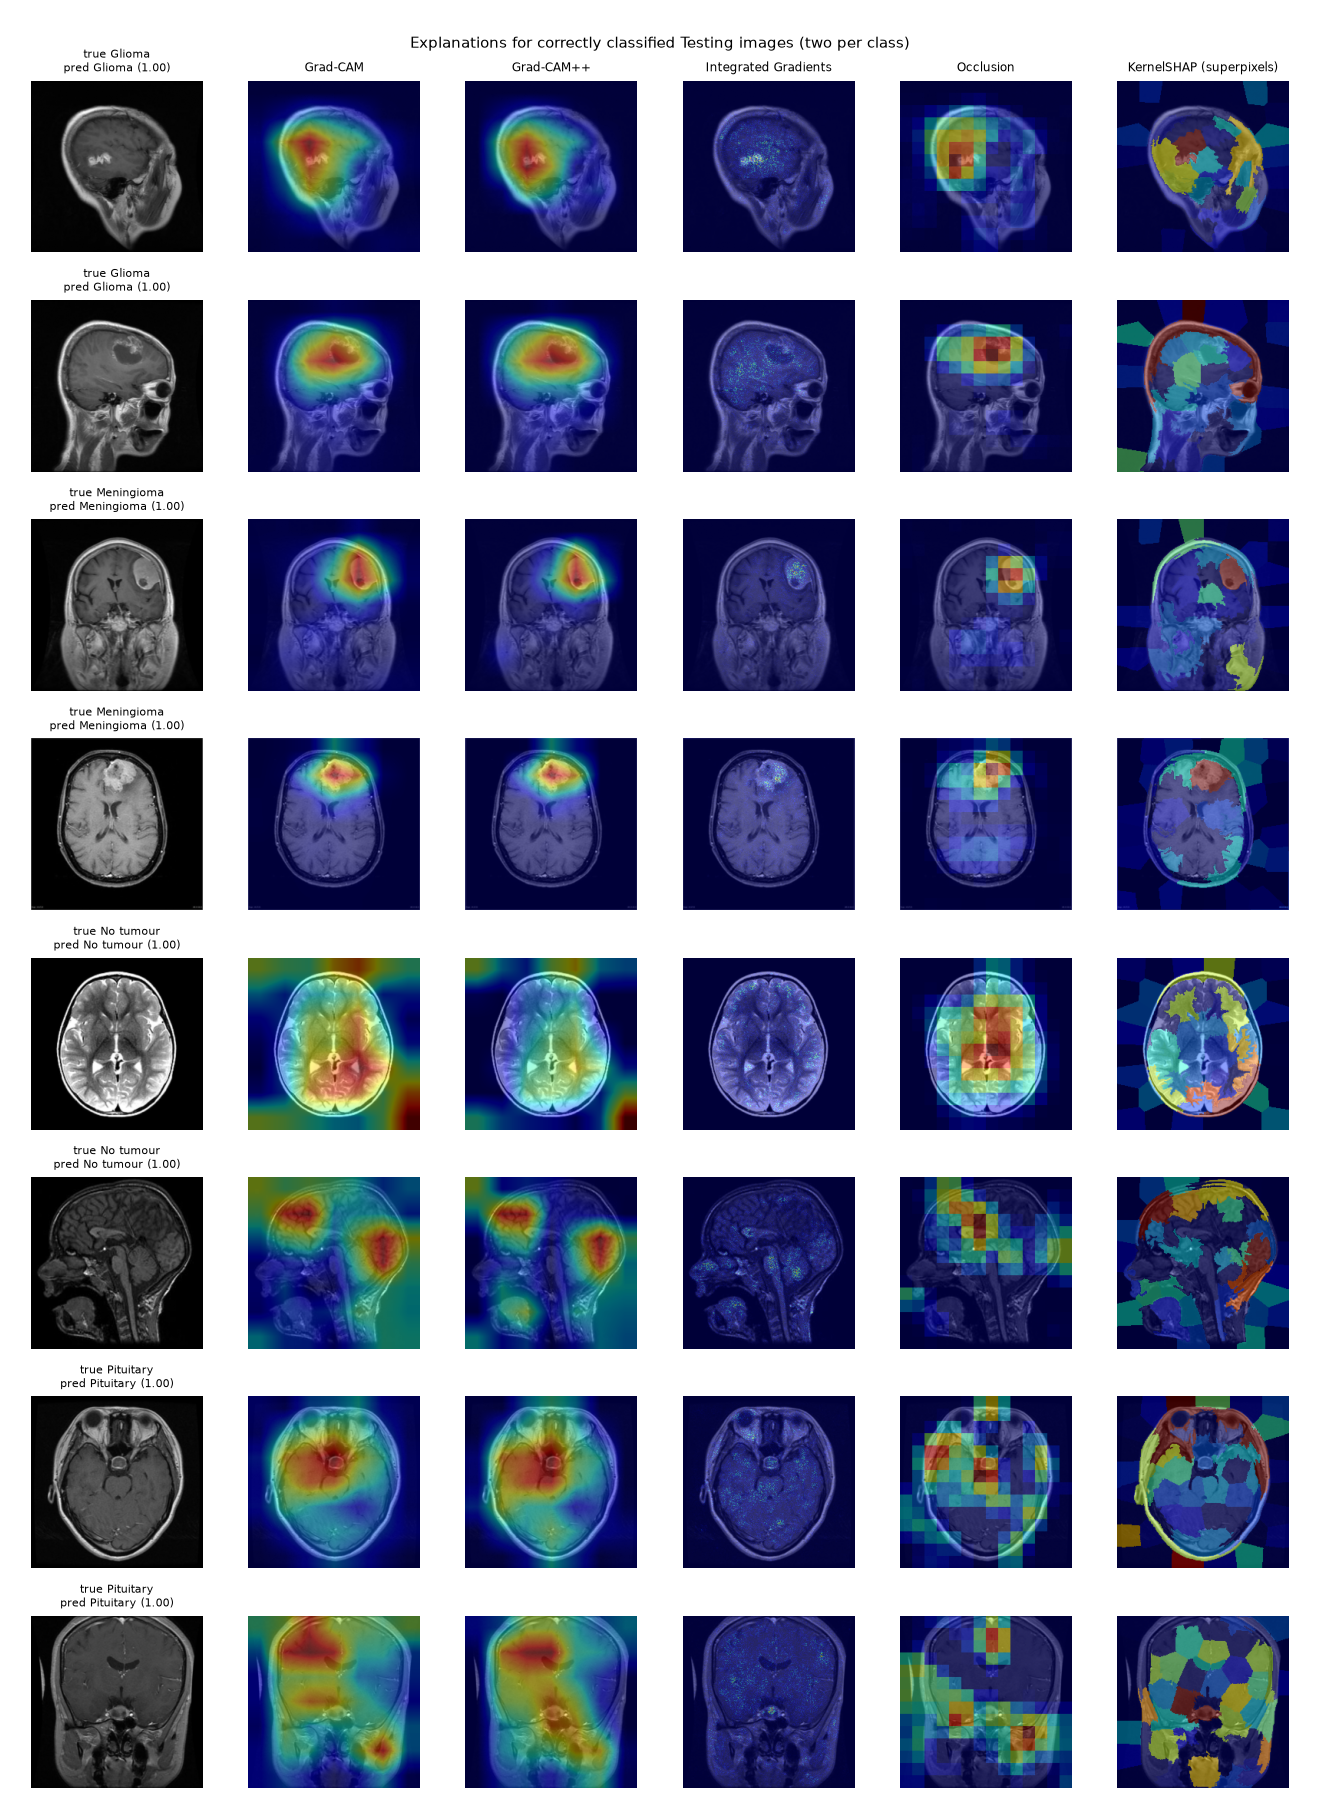

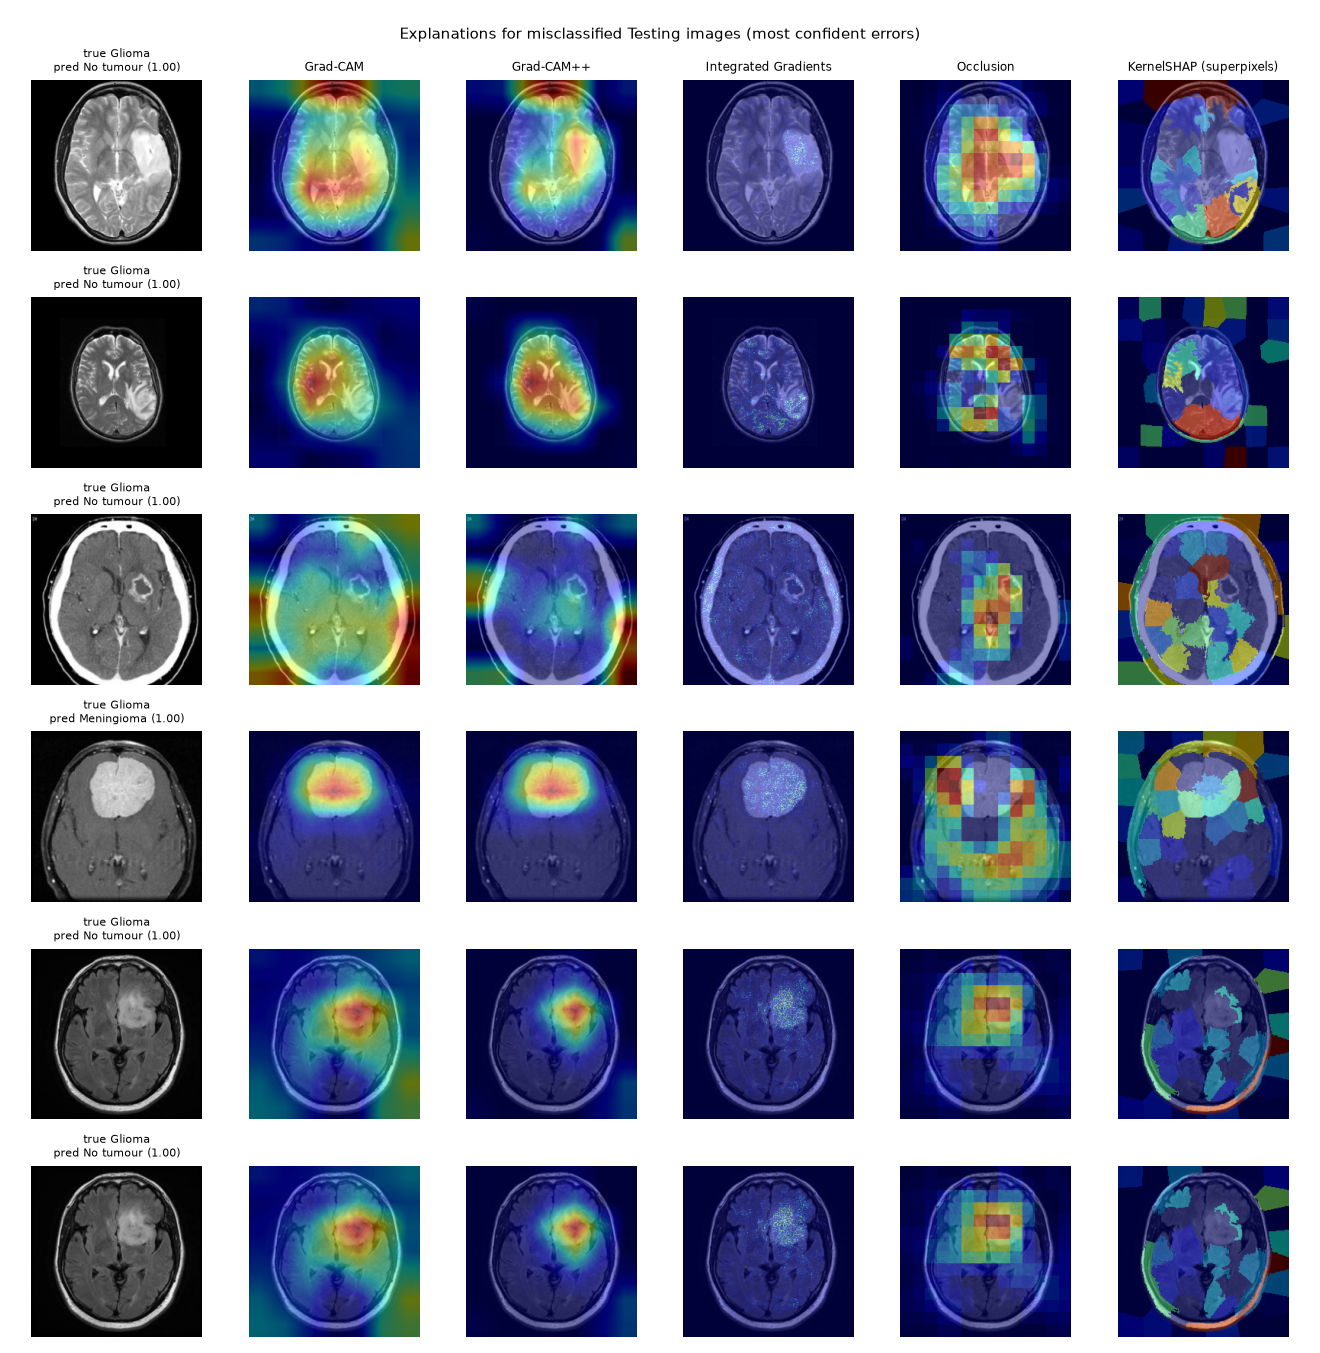

In [6]:
from IPython.display import Image, display
for f in ("xai_faithfulness", "xai_sanity_check", "xai_agreement", "xai_grid_correct", "xai_grid_misclassified"):
    if Path(f"results/figures/{f}.png").exists():
        display(Image(f"results/figures/{f}.png", width=900 if "grid" in f else 620))

### LIME (added in v2.1.1)
Same 100 images, target, SLIC superpixels (64 segments), black baseline and 200 samples as KernelSHAP; an exponential kernel (width 0.25) on the cosine distance between the binary superpixel vector and the all-on vector weights a ridge regression (alpha 1) on the class logit. Results are in separate files written by `scripts/run_lime.py`; the original five-method files are unchanged. The model-parameter randomisation test is run on the same 12 images. The data (label) randomisation test of Adebayo et al. would need retraining on shuffled labels and is not run; instead each map is compared with the maps for the other three classes.

,deletion_auc,insertion_auc,inside_foreground
method,,,
gradcam,0.487,0.841,0.792
gradcampp,0.490,0.842,0.840
integrated_gradients,0.283,0.679,0.978
kernel_shap,0.400,0.749,0.765
lime,0.363,0.777,0.806
occlusion,0.466,0.803,0.827
random,0.283,0.497,0.579


,LIME
stage,
classifier,-0.031
conv_head,0.041
blocks.6,0.055
blocks.4,0.156
blocks.2,-0.016
conv_stem,-0.018


,gradcam,gradcampp,integrated_gradients,occlusion,kernel_shap,lime
gradcam,1.00,0.84,0.51,0.38,0.22,0.31
gradcampp,0.84,1.00,0.58,0.31,0.22,0.30
integrated_gradients,0.51,0.58,1.00,0.31,0.28,0.34
occlusion,0.38,0.31,0.31,1.00,0.18,0.22
kernel_shap,0.22,0.22,0.28,0.18,1.00,0.47
lime,0.31,0.30,0.34,0.22,0.47,1.00


target-class sensitivity (mean Spearman with other-class maps): {'gradcam': -0.0, 'gradcampp': 0.92, 'integrated_gradients': 0.94, 'occlusion': -0.18, 'kernel_shap': -0.2, 'lime': -0.15}
seed stability (mean Spearman between seeds): {'lime': 0.7, 'kernel_shap': 0.42}


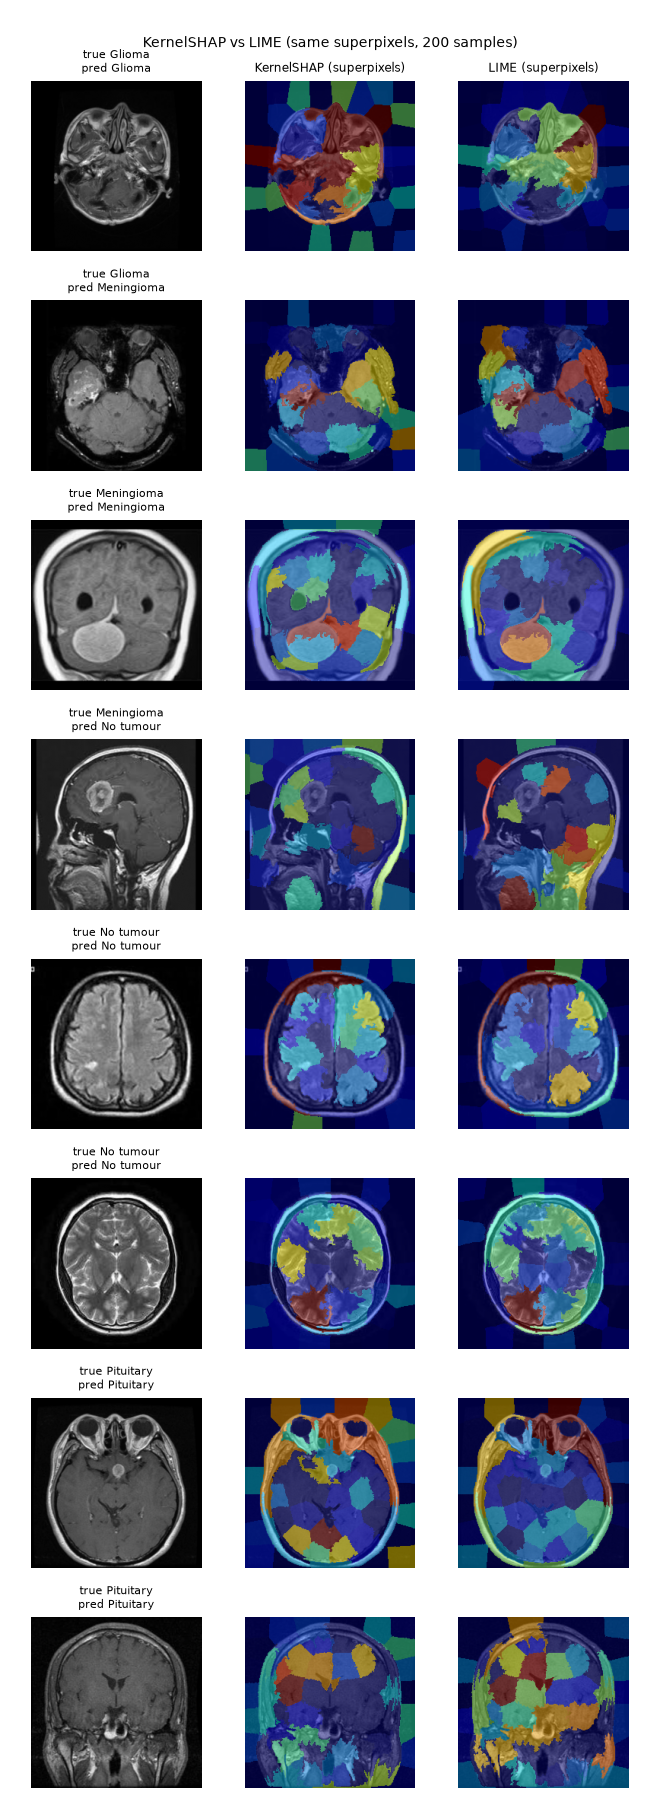

In [7]:
FORCE_LIME = False
if FORCE_LIME or not Path("results/xai/lime_summary.json").exists():
    subprocess.run([sys.executable, "scripts/run_lime.py"], check=True)
import json
lf = pd.read_csv("results/xai/lime_faithfulness_per_image.csv")
display(pd.concat([faith, lf[faith.columns]]).groupby("method")[["deletion_auc", "insertion_auc", "inside_foreground"]].mean().round(3))
display(pd.read_csv("results/xai/lime_sanity_cascading_randomisation.csv").groupby("stage", sort=False).spearman.mean().round(3).to_frame("LIME"))
display(pd.read_csv("results/xai/method_agreement_spearman_with_lime.csv", index_col=0).round(2))
ls = json.load(open("results/xai/lime_summary.json"))
print("target-class sensitivity (mean Spearman with other-class maps):", {k: round(v, 2) for k, v in ls["target_class_sensitivity_mean_spearman"].items()})
print("seed stability (mean Spearman between seeds):", {k: round(v, 2) for k, v in ls["seed_stability_mean_spearman"].items()})
display(Image("results/figures/xai_lime_examples.png", width=420))